<a href="https://colab.research.google.com/github/aishnori-abhyasi/AI-Product-Leader_Capstone/blob/main/AIPL_Capstone_AishNori_LogRegression_Lasso_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## This Colab notebook applies **Logistic Regression - Lasso - L1 Normalization** to a csv file of 10000 gig workers with their 90 days of UPI telemetry.
## Solver used is **'liblinear'** as L1 penalty can be applied only with this solver.


In [15]:
import numpy as np
import pandas as pd
## !pip install matplotlib-venn
import matplotlib
## matplotlib.use('TkAgg')
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

In [16]:
df = pd.read_csv("https://raw.githubusercontent.com/aishnori-abhyasi/AI-Product-Leader_Capstone/refs/heads/main/india_gigworker_90d_telemetry.csv")

# Calculate Net_Savings_90D (if not already present in the CSV) as it's a key component
# In this case, 'Net_Savings_90D' is already in the CSV, so no calculation needed here.

# To ensure a balanced target variable (two classes), we'll define Positive_Trend based on Net_Savings_90D relative to its median.
# This ensures a roughly 50/50 split of 0s and 1s, which is required for the Logistic Regression model.
median_net_savings_90d = df['Net_Savings_90D'].median()
df['Positive_Trend'] = (df['Net_Savings_90D'] > median_net_savings_90d).astype(int)

# Training model to apply Lasso Log Regression (l1)




In [17]:
X = df.drop(columns=['Positive_Trend', 'CustomerID', 'Archetype'])
y = df['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)
## Initialising Logistic Regression && Experimenting with Lasso Regression, so using liblinear solver for L1 normalization
trend_model = LogisticRegression(C=1.0,penalty="l1",solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

['Financial_Trend_Predictor.pkl']

# Extracting Coefficients for Compliance and Reason Codes




In [18]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
               Feature  Coefficient_Weight
2      Net_Savings_90D            0.000297
0     Total_Inflow_90D            0.000004
4  Leisure_Spend_Ratio            0.000000
3        Savings_Ratio            0.000000
5  Investment_Affinity            0.000000
1    Total_Outflow_90D           -0.000004


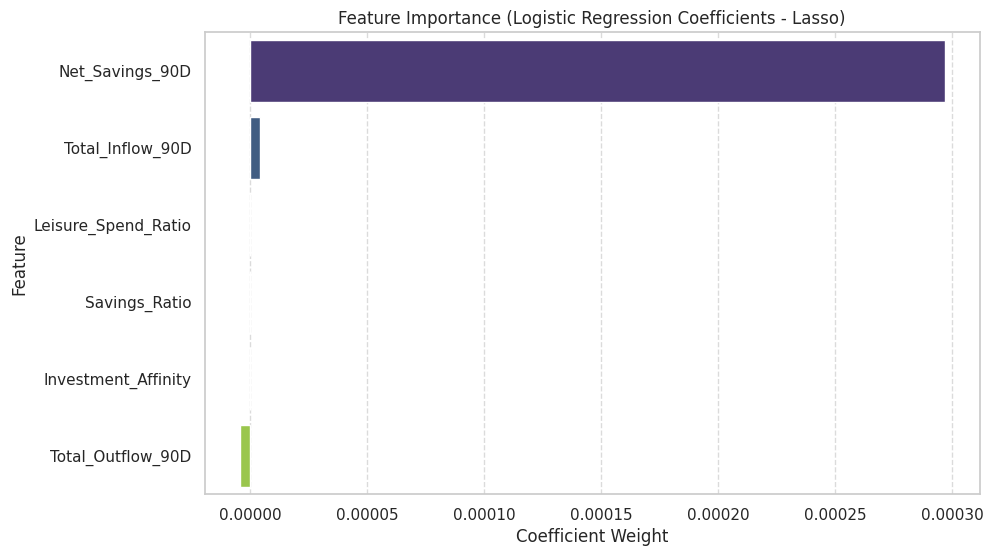

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient_Weight', y='Feature', data=coefficients, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Logistic Regression Coefficients - Lasso)')
plt.xlabel('Coefficient Weight')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

# Model Evaluation: Confusion Matrix

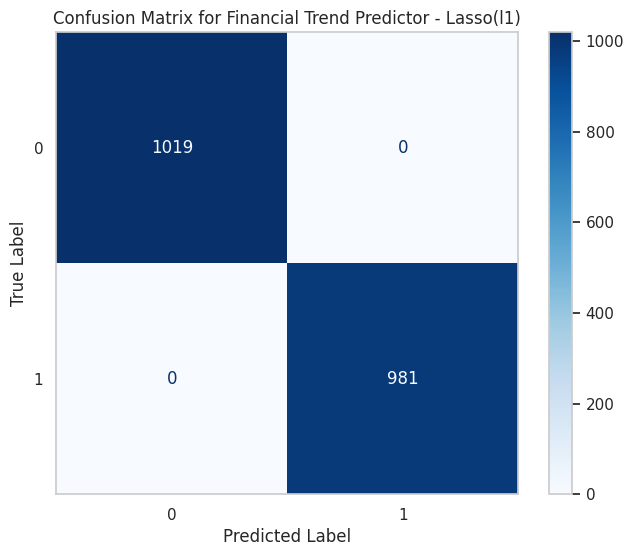

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the trained model
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=trend_model.classes_)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=trend_model.classes_)
display_cm.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix for Financial Trend Predictor - Lasso(l1)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()


# Accuracy, Precision, Recall and F1 Score calculation

In [21]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression # Added for model training

X = df.drop(columns=['Positive_Trend', 'CustomerID', 'Archetype'])
y = df['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

# Train the model (re-added for robustness)
trend_model = LogisticRegression(C=1.0,solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)

# Save the model (re-added for robustness, though not strictly needed if we use the object directly)
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

# Load the trained model (or just use trend_model directly, but keeping for consistency with original intent)
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Accuracy: 0.8240
Precision: 0.7551
Recall: 0.9490
F1 Score: 0.8410


# Model Evaluation: ROC-AUC Score and Curve

---



ROC-AUC Score: 0.9639


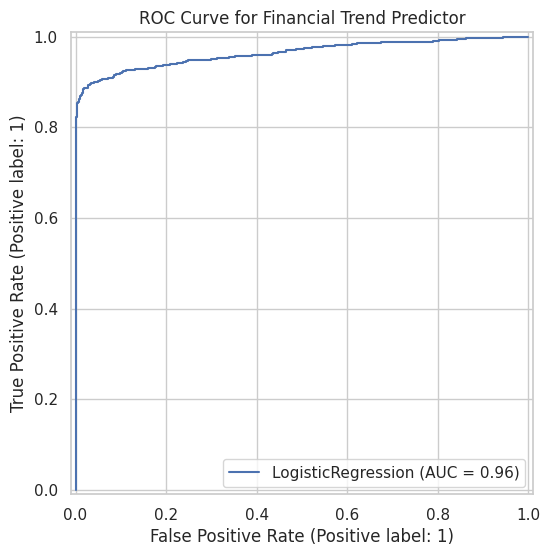

In [22]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Predict probabilities for the positive class (class 1)
y_pred_proba = trend_model.predict_proba(X_test)[:, 1]

# Calculate the ROC-AUC score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot the ROC curve
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(trend_model, X_test, y_test, ax=ax)
plt.title('ROC Curve for Financial Trend Predictor')
plt.grid(True)
plt.show()

# Now, after trend direction, plotting data with two major drivers




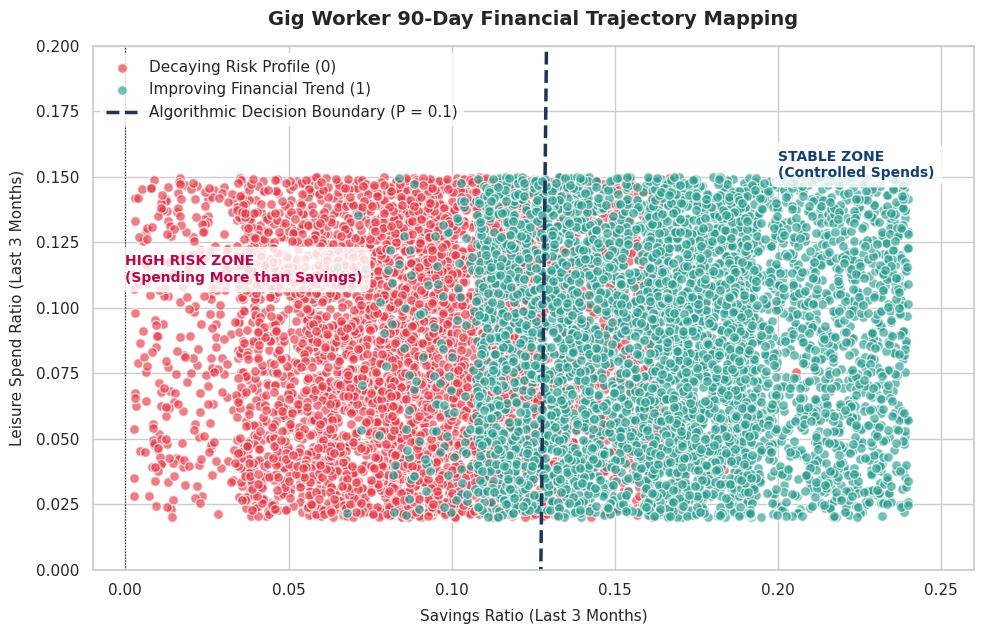

In [23]:
df_plot = pd.DataFrame({
  'Savings_Growth_data': df['Savings_Ratio'],
  'Discretionary_Spend_data': df['Leisure_Spend_Ratio']
})

# Use the 'Positive_Trend' column already calculated in the main df
df_plot['Positive_Trend'] = df['Positive_Trend']

X_plot = df_plot[['Savings_Growth_data','Discretionary_Spend_data']]
y_plot = df_plot['Positive_Trend']
trend_model_2D = LogisticRegression(solver='liblinear',random_state=42)
trend_model_2D.fit(X_plot,y_plot)
plt.figure(figsize=(10, 6.5))
sns.set_theme(style="whitegrid")

# Configure font to support Unicode characters like emojis
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Apple Color Emoji', 'Segoe UI Emoji', 'Noto Color Emoji']
plt.rcParams['font.family'] = 'sans-serif'

  # Define color palette for Indian FinBuddy app
colors = {0: "#E63946", 1: "#2A9D8F"} # Red = Decaying/Risky, Green = Improving/Healthy
labels = {0: "Decaying Risk Profile (0)", 1: "Improving Financial Trend (1)"}
for category in [0,1]:
    subset = df_plot[df_plot['Positive_Trend'] == category]
    plt.scatter(
        subset['Savings_Growth_data'],
        subset['Discretionary_Spend_data'],
        c=colors[category],
        label=labels[category],
        alpha=0.65,
        edgecolors='w',
        s=50
    )
    # --- CALCULATING THE DECISION BOUNDARY LINE ---
# The boundary occurs exactly where the model outputs P = 0.50 (log-odds = 0).
# Formula: w0*x + w1*y + bias = 0  =>  y = -(w0*x + bias) / w1
b = trend_model_2D.intercept_[0]
w1, w2 = trend_model_2D.coef_[0]
x_values = np.linspace(df_plot['Savings_Growth_data'].min(), df_plot['Savings_Growth_data'].max(), 100)
y_values = -(w1 * x_values + b) / w2
# Plot the linear decision boundary separating the zones
plt.plot(x_values, y_values, color="#1D3557", linestyle="--", linewidth=2.5, label="Algorithmic Decision Boundary (P = 0.1)")

# Set plot limits to properly display the range of ratio data
plt.xlim([-0.01, 0.26]) # Adjusted for Savings Ratio range
plt.ylim([-0.00, 0.20]) # Adjusted for Leisure Spend Ratio range

# Annotate regions to make the dashboard intuitive for risk auditors
# Adjusted text coordinates to match the data range and logical zones
plt.text(0.00, 0.11, "HIGH RISK ZONE\n(Spending More than Savings)",
    color="#B7094C", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
plt.text(0.20, 0.15, "STABLE ZONE\n(Controlled Spends)",
    color="#134074", fontsize=10, fontweight='bold', bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5'))
# Formatting Labels and Titles (Regulatory & Compliance Purpose)
plt.title("Gig Worker 90-Day Financial Trajectory Mapping", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Savings Ratio (Last 3 Months)", fontsize=11, labelpad=8)
plt.ylabel("Leisure Spend Ratio (Last 3 Months)", fontsize=11, labelpad=8)
plt.axhline(0, color='black', linewidth=0.8, linestyle=':')
plt.axvline(0, color='black', linewidth=0.8, linestyle=':')
plt.legend(loc="upper left", frameon=True, facecolor="white", edgecolor="none")
plt.tight_layout()
  # Save image file for the CI/CD documentation registry
plt.savefig('Finance_Trend.png', dpi=300)
plt.show()


# Increase the train_test split percentage to 50:50 ratio





In [24]:
X = df.drop(columns=['Positive_Trend', 'CustomerID', 'Archetype'])
y = df['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.5,random_state=42)
## Initialising Logistic Regression && Experimenting with Lasso Regression, so using liblinear solver for L1 normalization
trend_model = LogisticRegression(C=1.0,penalty="l1",solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

['Financial_Trend_Predictor.pkl']

In [25]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
               Feature  Coefficient_Weight
2      Net_Savings_90D            0.000193
0     Total_Inflow_90D            0.000003
4  Leisure_Spend_Ratio            0.000000
3        Savings_Ratio            0.000000
5  Investment_Affinity            0.000000
1    Total_Outflow_90D           -0.000004


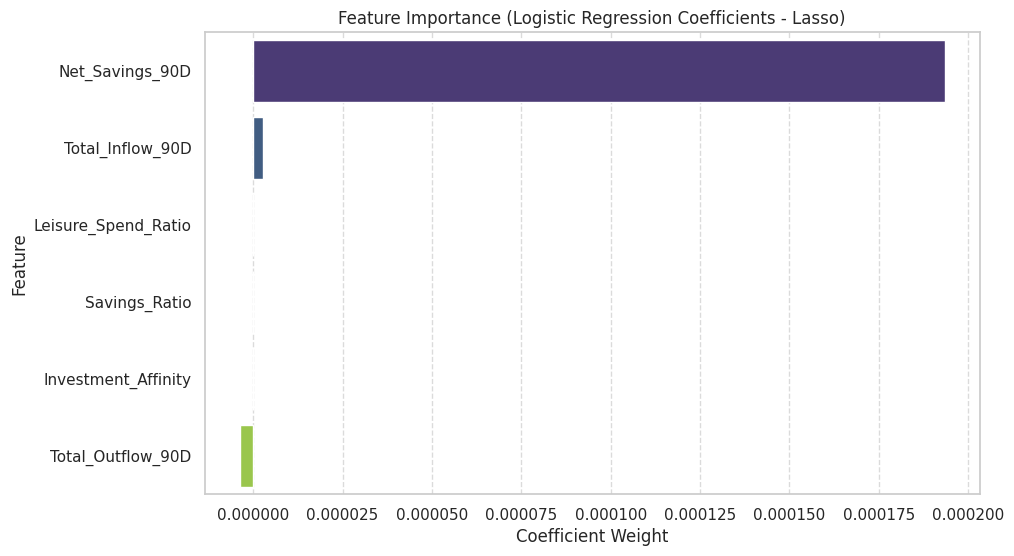

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient_Weight', y='Feature', data=coefficients, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Logistic Regression Coefficients - Lasso)')
plt.xlabel('Coefficient Weight')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

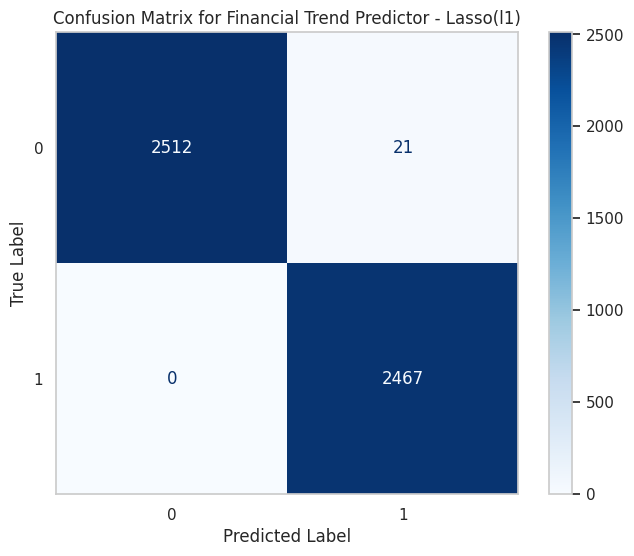

In [27]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the trained model
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=trend_model.classes_)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=trend_model.classes_)
display_cm.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix for Financial Trend Predictor - Lasso(l1)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()

In [29]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression # Added for model training

X = df.drop(columns=['Positive_Trend', 'CustomerID', 'Archetype'])
y = df['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.5,random_state=42)

# Train the model (re-added for robustness)
trend_model = LogisticRegression(C=1.0,solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)

# Save the model (re-added for robustness, though not strictly needed if we use the object directly)
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

# Load the trained model (or just use trend_model directly, but keeping for consistency with original intent)
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Accuracy: 0.8274
Precision: 0.7582
Recall: 0.9546
F1 Score: 0.8451


ROC-AUC Score: 0.9668


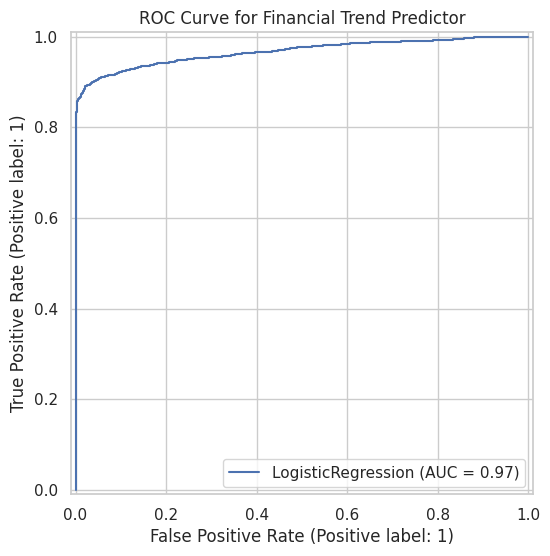

In [30]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Predict probabilities for the positive class (class 1)
y_pred_proba = trend_model.predict_proba(X_test)[:, 1]

# Calculate the ROC-AUC score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot the ROC curve
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(trend_model, X_test, y_test, ax=ax)
plt.title('ROC Curve for Financial Trend Predictor')
plt.grid(True)
plt.show()

# Increase the train_test split percentage to 80:20 ratio


In [32]:
X = df.drop(columns=['Positive_Trend', 'CustomerID', 'Archetype'])
y = df['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.8,random_state=42)
## Initialising Logistic Regression && Experimenting with Lasso Regression, so using liblinear solver for L1 normalization
trend_model = LogisticRegression(C=1.0,penalty="l1",solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)
## Saving the model
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

['Financial_Trend_Predictor.pkl']

In [33]:
print("📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) ")
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient_Weight': trend_model.coef_[0]
}).sort_values(by='Coefficient_Weight',ascending=False)
print(coefficients)

📈 LOGISTIC REGRESSION COEFFICIENTS (TREND DIRECTION) 
               Feature  Coefficient_Weight
2      Net_Savings_90D            0.000169
0     Total_Inflow_90D            0.000002
4  Leisure_Spend_Ratio            0.000000
3        Savings_Ratio            0.000000
5  Investment_Affinity            0.000000
1    Total_Outflow_90D           -0.000003


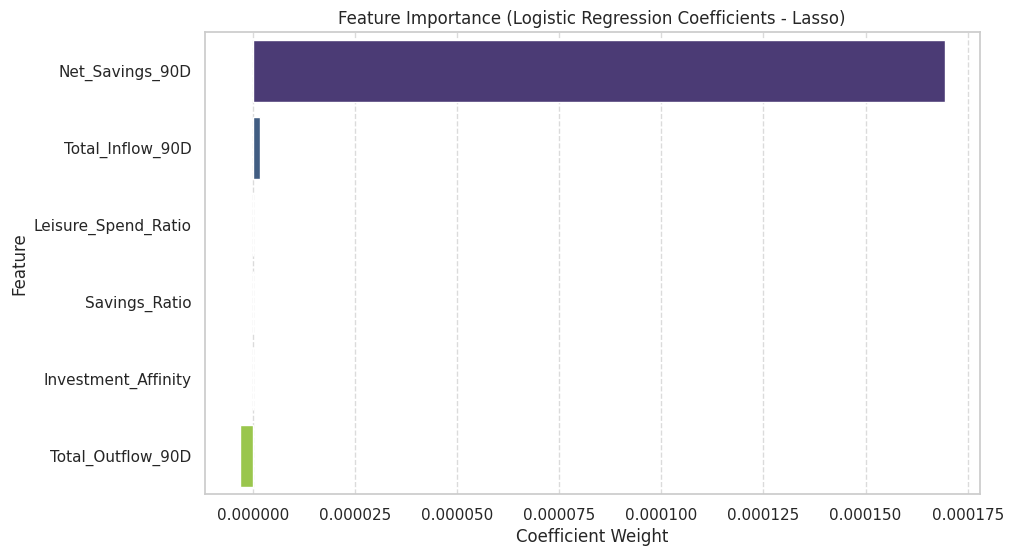

In [34]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.barplot(x='Coefficient_Weight', y='Feature', data=coefficients, palette='viridis', hue='Feature', legend=False)
plt.title('Feature Importance (Logistic Regression Coefficients - Lasso)')
plt.xlabel('Coefficient Weight')
plt.ylabel('Feature')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

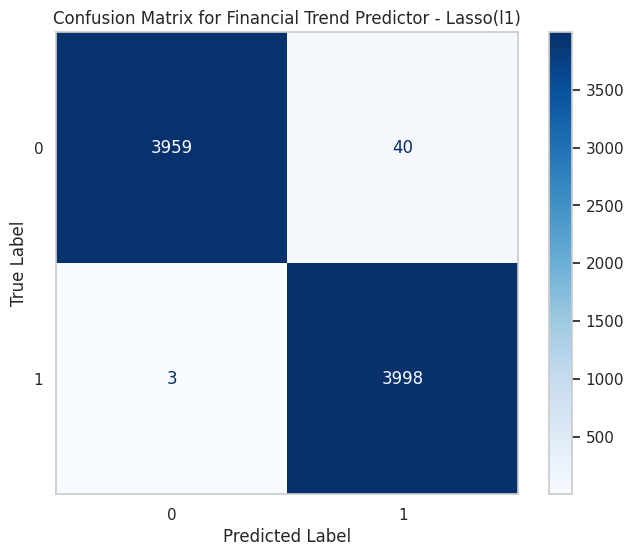

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Load the trained model
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=trend_model.classes_)

# Display the confusion matrix
fig, ax = plt.subplots(figsize=(8, 6))
display_cm = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=trend_model.classes_)
display_cm.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix for Financial Trend Predictor - Lasso(l1)')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.grid(False)
plt.show()

In [36]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import joblib
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression # Added for model training

X = df.drop(columns=['Positive_Trend', 'CustomerID', 'Archetype'])
y = df['Positive_Trend']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.8,random_state=42)

# Train the model (re-added for robustness)
trend_model = LogisticRegression(C=1.0,solver='liblinear',random_state=42)
trend_model.fit(X_train,y_train)

# Save the model (re-added for robustness, though not strictly needed if we use the object directly)
joblib.dump(trend_model,'Financial_Trend_Predictor.pkl')

# Load the trained model (or just use trend_model directly, but keeping for consistency with original intent)
trend_model = joblib.load('Financial_Trend_Predictor.pkl')

# Predict on the test set
y_pred = trend_model.predict(X_test)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Accuracy: 0.8297
Precision: 0.7658
Recall: 0.9503
F1 Score: 0.8481


ROC-AUC Score: 0.9639


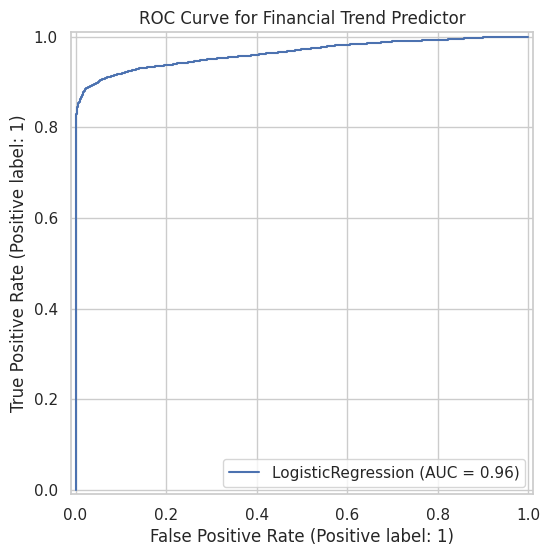

In [37]:
from sklearn.metrics import roc_auc_score, RocCurveDisplay

# Predict probabilities for the positive class (class 1)
y_pred_proba = trend_model.predict_proba(X_test)[:, 1]

# Calculate the ROC-AUC score
roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plot the ROC curve
fig, ax = plt.subplots(figsize=(8, 6))
RocCurveDisplay.from_estimator(trend_model, X_test, y_test, ax=ax)
plt.title('ROC Curve for Financial Trend Predictor')
plt.grid(True)
plt.show()